In [ ]:
import os, io
import torch
from torch import nn
from torchvision import models, transforms
from PIL import Image, ImageOps
from collections import Counter
from IPython.display import display, Audio
from google.colab import files

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

MODEL_PATH = "currency_resnet18_real.pth"
if not os.path.exists(MODEL_PATH):
    up = files.upload()                      # pick the .pth file you downloaded
    MODEL_PATH = list(up.keys())[0]

ckpt = torch.load(MODEL_PATH, map_location=device)
class_names = ckpt["classes"]

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(class_names))
model.load_state_dict(ckpt["model"])
model = model.to(device)
model.eval()

print("Model loaded. Classes:", class_names)

Using: cpu


Saving currency_resnet18_real (2).pth to currency_resnet18_real (2).pth
Model loaded. Classes: ['10', '100', '1000', '20', '5', '50', '500']


In [ ]:
!pip install gTTS -q
from gtts import gTTS   #for turning text to speech

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])


def load_photo(data):
    img = Image.open(io.BytesIO(data))
    img = ImageOps.exif_transpose(img)       # fix phone rotation
    return img.convert("RGB")


def predict_one(data, show=True):
    """One photo in -> (label, confidence from 0 to 1, all probabilities)."""
    img = load_photo(data)
    if show:
        preview = img.copy()
        preview.thumbnail((300, 300))
        display(preview)
    x = preprocess(img).unsqueeze(0).to(device)
    with torch.inference_mode():
        probs = torch.softmax(model(x), dim=1)[0].cpu()
    conf, idx = probs.max(dim=0)
    return class_names[idx.item()], conf.item(), probs


def speak(text):
    gTTS(text=text, lang="en").save("speech.mp3")
    display(Audio("speech.mp3", autoplay=True))

In [ ]:
def majority_vote(results):
    """results = list of (label, confidence).
    A note wins only if MORE THAN HALF of the photos say the same thing."""
    votes = Counter(label for label, _ in results)
    ranked = votes.most_common()
    best_label, best_count = ranked[0]
    tied = len(ranked) > 1 and ranked[1][1] == best_count
    if best_count > len(results) / 2 and not tied:
        return best_label, votes
    return None, votes


def identify_note():
    NUM_PHOTOS = 3   # always ask for 3 photos, every time

    msg = "Please take three photos of the note, from slightly different angles."
    print(msg)
    speak(msg)

    uploaded = files.upload()          # select exactly 3 photos
    items = list(uploaded.items())

    if len(items) < NUM_PHOTOS:
        msg = f"I need {NUM_PHOTOS} photos to be sure. Please try again."
        print(msg)
        speak(msg)
        return None

    if len(items) > NUM_PHOTOS:
        print(f"You selected {len(items)} photos, using only the first {NUM_PHOTOS}.")
        items = items[:NUM_PHOTOS]

    results = []
    for i, (name, data) in enumerate(items, start=1):
        lab, c, _ = predict_one(data)
        print(f"Photo {i}: {lab} rupees ({c * 100:.1f}% sure)")
        results.append((lab, c))

    winner, votes = majority_vote(results)
    print("Votes:", dict(votes))

    if winner is None:
        msg = "The photos do not agree. Please keep the note flat, in good light, and try again."
        print(msg)
        speak(msg)
        return None

    print(f"\nFinal answer: {winner} rupees ({votes[winner]} of {len(results)} photos agree)")
    speak(f"{winner} rupees")
    return winner

Please take three photos of the note, from slightly different angles.


Saving IMG_20261015_134852.jpg to IMG_20261015_134852.jpg
Saving IMG_20261015_134849.jpg to IMG_20261015_134849.jpg
Saving IMG_20261015_134848.jpg to IMG_20261015_134848.jpg


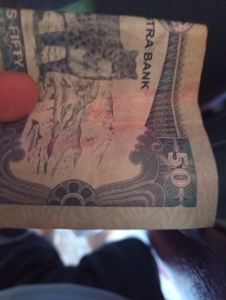

Photo 1: 50 rupees (100.0% sure)


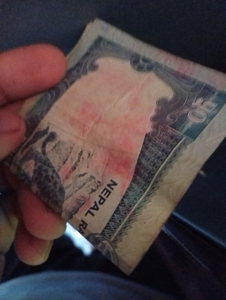

Photo 2: 50 rupees (100.0% sure)


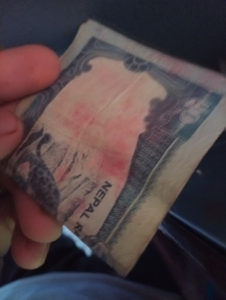

Photo 3: 50 rupees (100.0% sure)
Votes: {'50': 3}

Final answer: 50 rupees (3 of 3 photos agree)


In [ ]:
final = identify_note()